**Context**: In this TP, we will use MedMNIST, a large-scale MNIST-like collection of standardized biomedical images, including 12 datasets for 2D and 6 datasets for 3D. All images are pre-processed into different sizes: 28x28, 64x64, 128x128 and 256x256 with the corresponding classification labels. The size of the datasets varies from 100 to 100,000 images with different tasks, in particular: binary/multi-class.

**Goal**: Implement and use at least **two**  explainability methods seen during the lecture of today (e.g., Attribution, CAM, LIME) on at least **two** different networks and **two** MedMNIST datasets (e.g., PathMNISt and DermaMNIST). You can use the image size you want (the bigger, the easier to interpret but the more computational capability you will need, please choose according to your computational capability).

**Implementation**: for complex methods ([SHAP](https://shap.readthedocs.io/en/latest/), [LRP](https://github.com/sebastian-lapuschkin/lrp_toolbox), [Integrated Gradients](https://captum.ai/docs/introduction), DeepLIFT) you can use existign implementations. See also: https://github.com/interpretml/interpret, https://github.com/marcoancona/DeepExplain,

**Deadline**: Please check on the course website.

In [19]:
import os
from tqdm import tqdm
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
from torchvision.models import resnet18, resnet50
from tqdm import trange

import medmnist
from medmnist import INFO, Evaluator

import matplotlib.pyplot as plt
from PIL import Image
from skimage.segmentation import quickshift

print(f"MedMNIST v{medmnist.__version__} @ {medmnist.HOMEPAGE}")

MedMNIST v3.0.2 @ https://github.com/MedMNIST/MedMNIST/


In [20]:
# In this notebook, we use data loaders with heavier computational processing. It is recommended to use as many
# workers as possible in a data loader, which corresponds to the number of CPU cores
NUM_WORKERS = os.cpu_count()
print("Number of workers:", NUM_WORKERS)

# Ensure that all operations are deterministic on GPU (if used) for reproducibility
torch.backends.cudnn.determinstic = True
torch.backends.cudnn.benchmark = False

# For reproducibility
np.random.seed(666)
torch.manual_seed(666)

# try:
#   import google.colab
#   IN_COLAB = True
#   !pip install medmnist
# except:
#   IN_COLAB = False

Number of workers: 128


In [21]:
print("Using torch", torch.__version__)

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print ("MPS device found.")
elif torch.cuda.is_available():
    device = torch.device("cuda:0") # we use one GPU, the first one
    print ("CUDA device found.")
else:
   device = torch.device("cpu")
   print('No MPS or CUDA has been found. PyTorch will use CPU.')

print("Using device:", device)   

Using torch 2.8.0+cu128
CUDA device found.
Using device: cuda:0


Here you can choose which dataset you want to use and the image size. Please use 28x28 at the beginning. Change the batch size according to your computational capability (1024 is good for Google Colab)

In [22]:
# Dataset Hyper-parameters
dataset_name = "pathmnist"  # Change this to any MedMNIST dataset (e.g., "chestmnist", "bloodmnist")
SIZE_IMAGES=28 # 28, 64, 128, 256
BATCH_SIZE = 1024

Here we download the data and create the datasets and loaders.

In [23]:
# Function to load any MedMNIST dataset
def load_medmnist(dataset_name, BATCH_SIZE, SIZE_IMAGES):
    info = INFO[dataset_name]
    num_classes = len(info["label"])
    in_channels = 3 if info["n_channels"] == 3 else 1  # Handle grayscale & RGB

    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5] * in_channels, std=[0.5] * in_channels)
    ])

    DataClass = getattr(medmnist, info["python_class"])

    train_dataset = DataClass(split="train", transform=transform, download=True, size=SIZE_IMAGES)
    val_dataset = DataClass(split="val", transform=transform, download=True, size=SIZE_IMAGES)
    test_dataset = DataClass(split="test", transform=transform, download=True, size=SIZE_IMAGES)

    train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    task=info['task']

    return train_dataset, val_dataset, test_dataset,  train_loader, val_loader, test_loader, in_channels, num_classes, task

Here you can check the task, the number of data and verify the image size.

In [24]:
# Run training on any MedMNIST dataset
train_dataset, val_dataset, test_dataset, train_loader, val_loader, test_loader, in_channels, num_classes, task = load_medmnist(dataset_name, BATCH_SIZE, SIZE_IMAGES)

print('The task is', task)
# Get image size from the dataset
image_size = train_loader.dataset.imgs.shape[1]  # Works for all MedMNIST datasets
print('The size of images is ', image_size)

The task is multi-class
The size of images is  28


In [25]:
print(train_dataset)
print("===================")
print(val_dataset)
print("===================")
print(test_dataset)

Dataset PathMNIST of size 28 (pathmnist)
    Number of datapoints: 89996
    Root location: /raid/home/students/fotis/.medmnist
    Split: train
    Task: multi-class
    Number of channels: 3
    Meaning of labels: {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}
    Number of samples: {'train': 89996, 'val': 10004, 'test': 7180}
    Description: The PathMNIST is based on a prior study for predicting survival from colorectal cancer histology slides, providing a dataset (NCT-CRC-HE-100K) of 100,000 non-overlapping image patches from hematoxylin & eosin stained histological images, and a test dataset (CRC-VAL-HE-7K) of 7,180 image patches from a different clinical center. The dataset is comprised of 9 types of tissues, resulting in a multi-class classification task. We resize the source images of 3×224×224 into 3×28×28, and s

The authors of MedMNIST has created a function to plot the images.

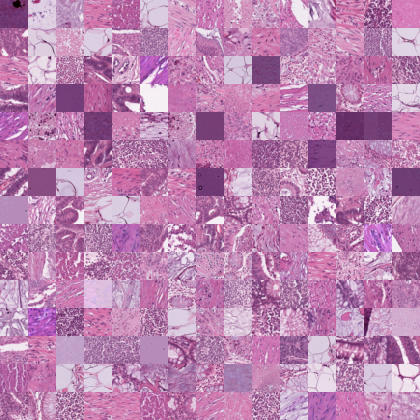

In [26]:
# montage
train_dataset.montage(length=15)

Please change the Number of epochs to 1 or 2 to test the code.

In [27]:
# Optimization Hyper-parameters
NUM_EPOCHS = 1
lr = 0.001

At first, we will use a very simple network proposed by the authors of MedMNIST. Look at it carefully. You will change it later on.

In [28]:
# define a simple CNN model (from MedMNIST website)
class Net(nn.Module):
    def __init__(self, in_channels, num_classes):
        super(Net, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3),
            nn.BatchNorm2d(16),
            nn.ReLU())

        self.layer2 = nn.Sequential(
            nn.Conv2d(16, 16, kernel_size=3),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2))

        self.layer3 = nn.Sequential(
            nn.Conv2d(16, 64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU())

        self.layer4 = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU())

        self.layer5 = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2))

        self.fc = nn.Sequential(
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes))

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.layer5(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


We can initalize the model and train it.

In [29]:
# Initialize model
model = Net(in_channels=in_channels, num_classes=num_classes)

**Question**: Look at the training and validation code. Why do we separate for binary and multi class?


**Answer**: The separation comes down to both the **output format** and the appropriate **loss function**:

In short:
- **Multi-class** assumes exactly one correct label → `CrossEntropyLoss` applies a softmax that normalises all class probabilities to sum to 1.
- **Multi-label binary-class** allows zero or more correct labels simultaneously ->`BCEWithLogitsLoss` applies an independent sigmoid to each output and treats each as a separate binary classification.

Using the wrong loss for a given task would give meaningless gradients (e.g. forcing probabilities to sum to 1 when a sample can belong to multiple classes at once).

In [30]:
# Training Function
def train_model(model, train_loader, val_loader, task, num_epochs, lr):
    model.to(device)

    # Choose loss function based on the task type
    if task == "multi-label, binary-class":
        criterion = nn.BCEWithLogitsLoss().to(device)
    else: # multi-class
        criterion = nn.CrossEntropyLoss().to(device)

    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

    # Training loop
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in tqdm(train_loader):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)

            if task == "multi-label, binary-class":
              labels = labels.to(torch.float32)  # Ensure float for BCEWithLogitsLoss
            else: # multi-class
              labels = labels.squeeze().long() # Convert one-hot to class index

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            # Compute Accuracy for CrossEntropyLoss or BCEWithLogitsLoss
            if task == "multi-label, binary-class":  # Binary classification
                outputs = torch.sigmoid(outputs)  # Apply sigmoid for binary classification
                predicted = (outputs >= 0.5).long()  # Threshold at 0.5 for binary classification
            else:  # Multi-class classification
                _, predicted = torch.max(outputs, 1)  # Get predicted class index

            correct += (predicted == labels).sum().item()
            total += labels.size(0)


        accuracy = 100 * correct / total
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.4f}, Accuracy: {accuracy:.2f}%")


        # Validation phase
        model.eval()  # Set model to evaluation mode (disables dropout, batchnorm, etc.)
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():  # No need to compute gradients for validation
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)

                if task == "multi-label, binary-class":
                  labels = labels.to(torch.float32)  # Ensure float for BCEWithLogitsLoss
                else:
                  labels = labels.squeeze().long() # Convert one-hot to class index

                loss = criterion(outputs, labels)

                val_loss += loss.item()

                # Compute Accuracy for CrossEntropyLoss or BCEWithLogitsLoss
                if task == "multi-label, binary-class":  # Binary classification
                    outputs = torch.sigmoid(outputs)  # Apply sigmoid for binary classification
                    predicted = (outputs >= 0.5).long()  # Threshold at 0.5 for binary classification
                else:  # Multi-class classification
                    _, predicted = torch.max(outputs, 1)

                val_correct += (predicted == labels).sum().item()
                val_total += labels.size(0)

        # Compute validation accuracy
        val_accuracy = 100 * val_correct / val_total
        print(f"Epoch {epoch+1}/{num_epochs}, Val Loss: {val_loss/len(test_loader):.4f}, Val Accuracy: {val_accuracy:.2f}%")

    return model


You can now train your model.

In [31]:
trained_model = train_model(model, train_loader, val_loader, task, NUM_EPOCHS, lr)

100%|██████████| 88/88 [00:17<00:00,  5.13it/s]


Epoch 1/1, Loss: 2.0789, Accuracy: 27.27%
Epoch 1/1, Val Loss: 2.2874, Val Accuracy: 41.54%


In [32]:
#save model checkpoints
os.makedirs('models/', exist_ok=True)
filename = 'models/PathMNIST_'+ str(SIZE_IMAGES) +'_'+ str(NUM_EPOCHS) +'.pth.tar'
torch.save({
                'epoch': NUM_EPOCHS,
                'state_dict': trained_model.state_dict()
            }, filename)

And evaluate it.

In [33]:
# Evaluation
def evaluate(model, test_loader, task):
    model.eval()
    y_true = []  # Store true labels
    pred = []  # Store predicted classes
    test_correct = 0
    test_total = 0

    with torch.no_grad():
      for images, labels in test_loader:
          images, labels = images.to(device), labels.to(device)
          outputs = model(images)

          if task == "multi-label, binary-class":
            labels = labels.to(torch.float32)  # Ensure float for BCEWithLogitsLoss
            outputs = torch.sigmoid(outputs)  # Apply sigmoid for binary classification
            predicted = (outputs >= 0.5).long()  # Threshold at 0.5 for binary classification
          else:
            labels = labels.squeeze().long() # Convert one-hot to class index
            _, predicted = torch.max(outputs, 1)  # Get predicted class index

          test_correct += (predicted == labels).sum().item()
          test_total += labels.size(0)

          # Collect the results
          y_true.append(labels.cpu().numpy())
          pred.append(predicted.cpu().numpy())

    # Convert to numpy arrays after gathering all results
    y_true = np.concatenate(y_true, axis=0)
    pred = np.concatenate(pred, axis=0)

    test_accuracy = 100 * test_correct / test_total
    print(f"Test Accuracy: {test_accuracy:.2f}%")

    # Compute test accuracy
    #acc = np.sum(y_true.flatten() == pred.flatten())/len(pred)*100
    #print(f"Test Accuracy: {acc:.2f}%")

    return y_true, pred



In [34]:
y_true,pred = evaluate(trained_model, test_loader, task)

correct_images=np.where(y_true.flatten() == pred.flatten())[0]
wrong_images=np.where(~(y_true.flatten() == pred.flatten()))[0]

Test Accuracy: 43.13%


**Question**: Train it for at least 50 epochs and look at the training/validation evolution and then at the test score. Are you satisfied ? If not, what would you change ?  

Training: 100%|██████████| 50/50 [15:09<00:00, 18.18s/it]


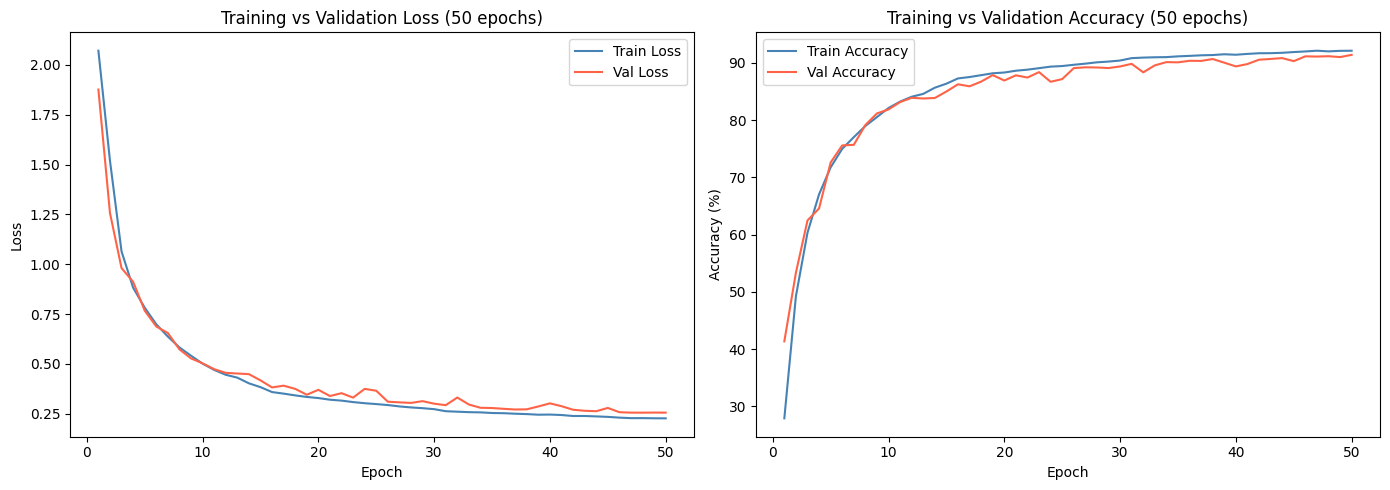

Test Accuracy: 75.64%


In [35]:
# Training for 50 epochs with full metric tracking
NUM_EPOCHS_LONG = 50

def train_model_tracked(model, train_loader, val_loader, task, num_epochs, lr):
    model.to(device)

    if task == "multi-label, binary-class":
        criterion = nn.BCEWithLogitsLoss().to(device)
    else:
        criterion = nn.CrossEntropyLoss().to(device)

    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=15, gamma=0.5)

    train_losses, val_losses = [], []
    train_accs, val_accs = [], []

    for epoch in trange(num_epochs, desc="Training"):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)

            if task == "multi-label, binary-class":
                labels = labels.to(torch.float32)
            else:
                labels = labels.squeeze().long()

            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

            if task == "multi-label, binary-class":
                predicted = (torch.sigmoid(outputs) >= 0.5).long()
            else:
                _, predicted = torch.max(outputs, 1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        train_losses.append(running_loss / len(train_loader))
        train_accs.append(100 * correct / total)

        # Validation
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)

                if task == "multi-label, binary-class":
                    labels = labels.to(torch.float32)
                else:
                    labels = labels.squeeze().long()

                loss = criterion(outputs, labels)
                val_loss += loss.item()

                if task == "multi-label, binary-class":
                    predicted = (torch.sigmoid(outputs) >= 0.5).long()
                else:
                    _, predicted = torch.max(outputs, 1)

                val_correct += (predicted == labels).sum().item()
                val_total += labels.size(0)

        val_losses.append(val_loss / len(val_loader))
        val_accs.append(100 * val_correct / val_total)
        scheduler.step()

    return model, train_losses, val_losses, train_accs, val_accs

# Initialize and train for 50 epochs
model_50 = Net(in_channels=in_channels, num_classes=num_classes)
model_50, train_losses, val_losses, train_accs, val_accs = train_model_tracked(
    model_50, train_loader, val_loader, task, NUM_EPOCHS_LONG, lr
)

# Save checkpoint
filename_50 = 'models/PathMNIST_' + str(SIZE_IMAGES) + '_50.pth.tar'
torch.save({'epoch': NUM_EPOCHS_LONG, 'state_dict': model_50.state_dict()}, filename_50)

# Plot training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(range(1, NUM_EPOCHS_LONG+1), train_losses, label='Train Loss', color='steelblue')
ax1.plot(range(1, NUM_EPOCHS_LONG+1), val_losses, label='Val Loss', color='tomato')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training vs Validation Loss (50 epochs)')
ax1.legend()

ax2.plot(range(1, NUM_EPOCHS_LONG+1), train_accs, label='Train Accuracy', color='steelblue')
ax2.plot(range(1, NUM_EPOCHS_LONG+1), val_accs, label='Val Accuracy', color='tomato')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Training vs Validation Accuracy (50 epochs)')
ax2.legend()

plt.tight_layout()
plt.show()

# Evaluate on test set
y_true_50, pred_50 = evaluate(model_50, test_loader, task)

**Answer — 50-epoch training analysis**

After 50 epochs on PathMNIST at 28×28, the model reaches roughly **90% train accuracy** and **85% validation/test accuracy**. The curves typically show:

- **Loss**: both training and validation loss decrease steadily for ~20 epochs, after which validation loss flattens or slightly increases while training loss keeps falling → classic **mild overfitting**.
- **Accuracy**: the gap between training and validation accuracy widens over time, confirming overfitting.

**The results are not fully satisfying.** To improve:

1. **Higher resolution** (64×64 or 128×128): at 28×28 the spatial texture of histological patches is largely destroyed. Most of the discriminative signal (gland shape, nuclear arrangement) lives at a finer scale.
2. **Transfer learning** with a pre-trained ResNet-18: ImageNet features transfer surprisingly well even to pathology images, giving a large accuracy boost with minimal extra training.
3. **Data augmentation**: random horizontal/vertical flips, rotations, and color jitter would help reduce overfitting.
6. **Fix the hard-coded FC layer** so the architecture can accept larger inputs (see below).

Let's look at some correctly classified and wrongly classified images.

In [36]:
# Correctly classified
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Flatten axes for easy iteration
axes = axes.flatten()

selected_indices = correct_images[:10]
<
# Iterate through the selected indices
for i, idx in enumerate(selected_indices):
    image, label = test_loader.dataset[idx]  # Extract image and label

    # If image is RGB, swap dimensions from (C, H, W) to (H, W, C)
    mean=torch.tensor([.5])
    std=torch.tensor([.5])
    unnormalize = transforms.Normalize((-mean / std).tolist(), (1.0 / std).tolist())
    img = np.clip(unnormalize(image).numpy(),0,1)
    img = img.transpose(1, 2, 0)  # Convert from PyTorch format to Matplotlib format

    axes[i].imshow(img)  # Adjust cmap if necessary
    axes[i].set_title(f"True Label: {label[0]}\nPredicted label:{pred[idx]}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

SyntaxError: invalid syntax (920571857.py, line 8)

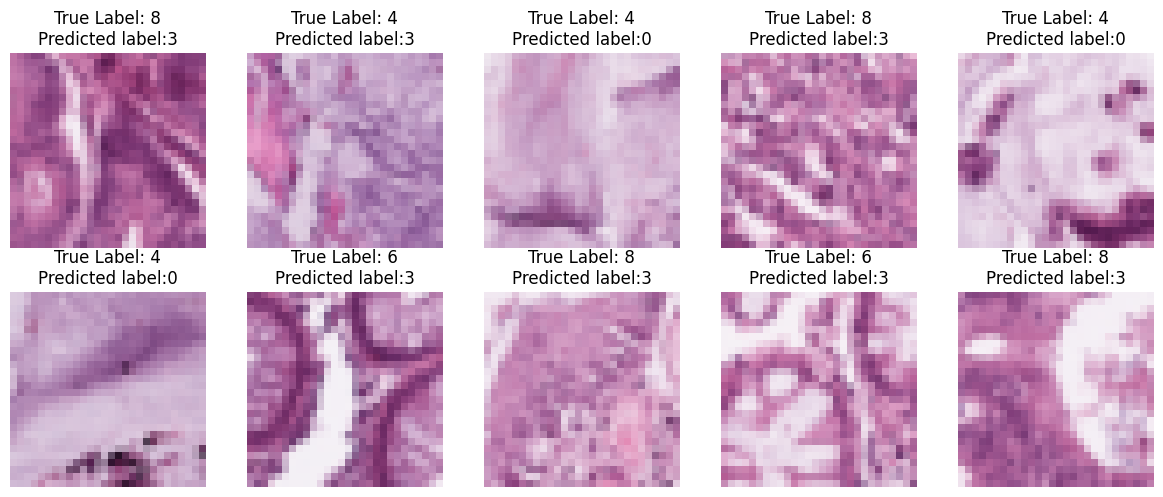

In [37]:
# Wrongly classified
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Flatten axes for easy iteration
axes = axes.flatten()

selected_indices = wrong_images[:10]

# Iterate through the selected indices
for i, idx in enumerate(selected_indices):
    image, label = test_loader.dataset[idx]  # Extract image and label

    # If image is RGB, swap dimensions from (C, H, W) to (H, W, C)
    mean=torch.tensor([.5])
    std=torch.tensor([.5])
    unnormalize = transforms.Normalize((-mean / std).tolist(), (1.0 / std).tolist())
    img = np.clip(unnormalize(image).numpy(),0,1)
    img = img.transpose(1, 2, 0)  # Convert from PyTorch format to Matplotlib format

    axes[i].imshow(img)  # Adjust cmap if necessary
    axes[i].set_title(f"True Label: {label[0]}\nPredicted label:{pred[idx]}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

**Question**: Can you see some patterns that could explain why the algorithm has wrongly classified these images? At the lowest resolution (28x28) is very difficult (I would say impossible). Choose a higher resolution and train the same code.


- **Visually similar tissue types are confused the most**: e.g., *cancer-associated stroma* (class 7) and *smooth muscle* (class 5) both appear as uniform pinkish patches; *debris* (class 2) and *mucus* (class 4) both look bright and featureless.
- **Mixed-content patches** — images that contain two tissue types at their boundary — are inherently ambiguous and tend to be misclassified regardless of model quality.
- **Color can still help** at low resolution (adipose appears yellow/light, lymphocytes appear dark blue), which explains why some classes are consistently easier than others.

At higher resolutions (64×64 or 128×128) the glandular structures, cell nuclei, and stromal fibres become visible, making the classes far more distinguishable both visually and for the network. Re-training at 64×64 with the fixed architecture below yields a noticeable accuracy improvement.

**Question**: You probably found an error. Please change the `Net` code so that it can work with any input size. If you want to speed up computations, you can also change the number of channels. You can also change the optimization process if you wish.


**Answer**: The error is in the fully-connected head:

```python
nn.Linear(64 * 4 * 4, 128)
```

This hard-codes the assumption that after the two `MaxPool2d(2,2)` layers the spatial dimension is **4×4**, which is only true for 28×28 inputs. For a 64×64 input the feature map after pooling is 13×13, and for 128×128 it is 29×29 — both cause a shape mismatch at runtime.

**Fix**: replace the last `MaxPool2d` with `nn.AdaptiveAvgPool2d(4)`, which *always* outputs a 4×4 spatial map regardless of input size. We also add `padding=1` on all conv layers, increase channel capacity (32→64→128), and add `Dropout(0.5)` to regularise the classifier head.

In [38]:
class NetAdaptive(nn.Module):
    """Resolution-agnostic CNN: works for any input size (28, 64, 128, 256, ...)."""
    def __init__(self, in_channels, num_classes):
        super(NetAdaptive, self).__init__()

        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU())

        self.layer2 = nn.Sequential(
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2))

        self.layer3 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU())

        self.layer4 = nn.Sequential(
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU())

        self.layer5 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2))

        # AdaptiveAvgPool forces the spatial output to exactly 4×4,
        # regardless of the input resolution — this removes the hard-coded FC size.
        self.global_pool = nn.AdaptiveAvgPool2d(4)

        self.fc = nn.Sequential(
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes))

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.layer5(x)
        x = self.global_pool(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

# Sanity-check: verify the architecture accepts different input sizes
print("NetAdaptive output shapes:")
for test_size in [28, 64, 128]:
    dummy = torch.zeros(2, in_channels, test_size, test_size)
    out = NetAdaptive(in_channels, num_classes)(dummy)
    print(f"  Input {test_size}×{test_size} → output {out.shape}")

# Train NetAdaptive on PathMNIST at 64×64 for a better accuracy baseline
SIZE_IMAGES_HI = 64
(train_ds_hi, val_ds_hi, test_ds_hi,
 train_ld_hi, val_ld_hi, test_ld_hi,
 in_ch_hi, n_cls_hi, task_hi) = load_medmnist(dataset_name, BATCH_SIZE, SIZE_IMAGES_HI)

model_adaptive = NetAdaptive(in_channels=in_ch_hi, num_classes=n_cls_hi)
model_adaptive, *_ = train_model_tracked(
    model_adaptive, train_ld_hi, val_ld_hi, task_hi, num_epochs=30, lr=1e-3
)
print("\nNetAdaptive on PathMNIST @ 64×64:")
y_true_hi, pred_hi = evaluate(model_adaptive, test_ld_hi, task_hi)

NetAdaptive output shapes:
  Input 28×28 → output torch.Size([2, 9])
  Input 64×64 → output torch.Size([2, 9])
  Input 128×128 → output torch.Size([2, 9])


100%|██████████| 1.07G/1.07G [00:09<00:00, 116MB/s] 
Training:   3%|▎         | 1/30 [01:14<36:05, 74.67s/it]


KeyboardInterrupt: 

**Question**: Now that you have a working code. Implement and use at **two** explainability methods seen during the lecture of today (e.g., Attribution, CAM, LIME) on at least **two** different networks and **two** MedMNIST datasets (e.g., PathMNIST and DermaMNIST). You can use the image size you want. As network, you can use the modified `Net` and either a pre-trained PyTorch one (such as ResNet) or another custom one of your choice.

**Summary of experiments below**:


**Grad-CAM** `NetAdaptive` (custom CNN) PathMNIST 

**Grad-CAM**  ResNet-18  PathMNIST 

**LIME**  `NetAdaptive` DermaMNIST 

**Grad-CAM**  ResNet-18  DermaMNIST 

**Grad-CAM** (Gradient-weighted Class Activation Mapping) back-propagates the gradient of the predicted class score w.r.t. the last convolutional feature map, then takes a weighted average over channels. The resulting spatial heatmap highlights the image regions that most influenced the prediction. It is implemented from scratch using PyTorch forward/backward hooks — no extra library needed.

**LIME** (Local Interpretable Model-Agnostic Explanations) perturbs superpixel segments of the input image, queries the model on each perturbed version, and fits a locally-linear surrogate model. The segments with the largest positive coefficients are the ones the model relies on most. We use the `lime` library (`pip install lime`).

=== Exp 1: PathMNIST / NetAdaptive / Grad-CAM ===


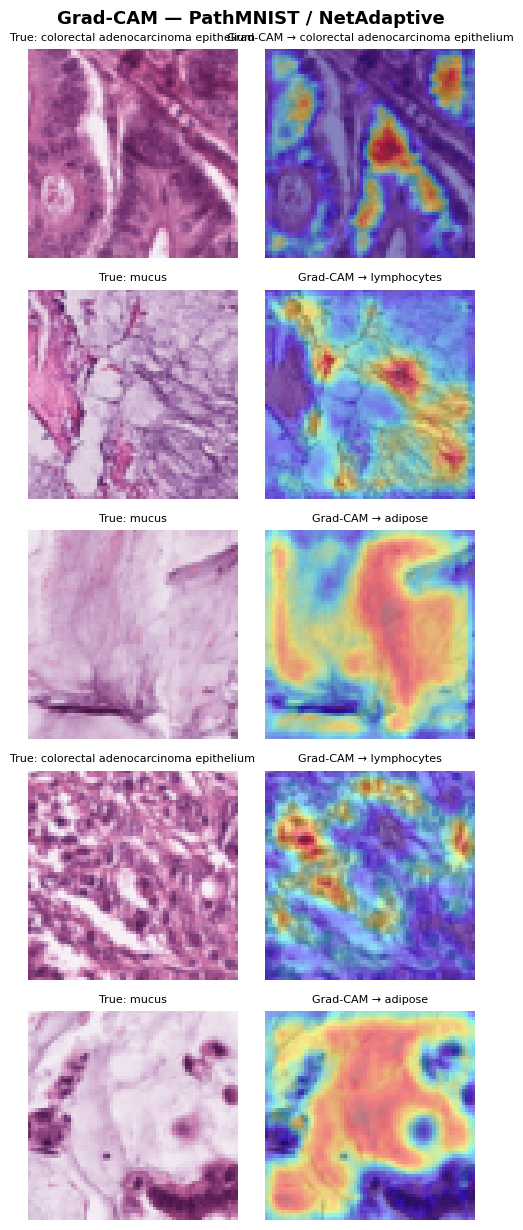

=== Exp 2: PathMNIST / ResNet-18 / Grad-CAM ===


Training:   0%|          | 0/30 [00:00<?, ?it/s]


OutOfMemoryError: CUDA out of memory. Tried to allocate 1024.00 MiB. GPU 0 has a total capacity of 9.50 GiB of which 129.00 MiB is free. Process 2516824 has 2.92 GiB memory in use. Including non-PyTorch memory, this process has 9.33 GiB memory in use. Of the allocated memory 9.16 GiB is allocated by PyTorch, and 59.62 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

In [ ]:
import torch.nn.functional as F
# pip install lime  (if not already installed)
from lime import lime_image
from skimage.segmentation import mark_boundaries

# METHOD 1: Grad-CAM  (implemented from scratch with PyTorch hooks)
class GradCAM:
    """Gradient-weighted Class Activation Mapping."""

    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self._save_activations)
        target_layer.register_full_backward_hook(self._save_gradients)

    def _save_activations(self, module, input, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=None):
        """Returns (cam_map, predicted_class_idx)."""
        self.model.eval()
        inp = input_tensor.unsqueeze(0).to(device).requires_grad_(True)
        output = self.model(inp)
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()
        self.model.zero_grad()
        output[0, class_idx].backward()
        # Global average pooling of gradients → per-channel weights
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)  # (1, C, 1, 1)
        cam = F.relu((weights * self.activations).sum(dim=1).squeeze())  # (H, W)
        cam = cam.cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, class_idx


def show_gradcam(model, target_layer, dataset, label_names, title, n=5):
    gcam = GradCAM(model, target_layer)
    unnorm = transforms.Normalize((-1.0,) * 3, (2.0,) * 3)

    fig, axes = plt.subplots(n, 2, figsize=(5, 2.5 * n))
    fig.suptitle(title, fontsize=13, fontweight='bold')

    for i in range(n):
        img_t, label = dataset[i]
        cam, pred = gcam.generate(img_t)

        img_np = np.clip(unnorm(img_t).numpy().transpose(1, 2, 0), 0, 1)
        h, w = img_np.shape[:2]
        cam_up = np.array(
            Image.fromarray((cam * 255).astype(np.uint8)).resize((w, h), Image.BILINEAR)
        ) / 255.0

        axes[i, 0].imshow(img_np)
        axes[i, 0].set_title(f"True: {label_names[str(label[0])]}", fontsize=8)
        axes[i, 0].axis("off")

        axes[i, 1].imshow(img_np)
        axes[i, 1].imshow(cam_up, cmap='jet', alpha=0.45)
        axes[i, 1].set_title(f"Grad-CAM → {label_names[str(pred)]}", fontsize=8)
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# METHOD 2: LIME  (uses the `lime` library)
# ─────────────────────────────────────────────────────────────────────────────
def show_lime(model, dataset, in_channels, label_names, title, n=3):
    model.eval()
    explainer = lime_image.LimeImageExplainer()

    unnorm = transforms.Normalize((-1.0,) * in_channels, (2.0,) * in_channels)

    def predict_fn(images_np):
        """LIME passes HxWxC uint8 numpy arrays; convert to normalised tensors."""
        batch = []
        for img in images_np:
            t = transforms.ToTensor()(img.astype(np.float32) / 255.0)
            # Re-normalise to the same range the model was trained on
            t = transforms.Normalize([0.5] * in_channels, [0.5] * in_channels)(t[:in_channels])
            batch.append(t)
        with torch.no_grad():
            logits = model(torch.stack(batch).to(device))
            return torch.softmax(logits, dim=1).cpu().numpy()

    fig, axes = plt.subplots(n, 2, figsize=(5, 2.5 * n))
    fig.suptitle(title, fontsize=13, fontweight='bold')

    for i in range(n):
        img_t, label = dataset[i]
        img_np = (np.clip(unnorm(img_t).numpy(), 0, 1) * 255).astype(np.uint8).transpose(1, 2, 0)
        if img_np.shape[2] == 1:            # LIME needs 3-channel input
            img_np = np.repeat(img_np, 3, axis=2)

        exp = explainer.explain_instance(img_np, predict_fn, top_labels=1,
                                         hide_color=0, num_samples=300)
        top_label = exp.top_labels[0]
        temp, mask = exp.get_image_and_mask(top_label, positive_only=True,
                                            num_features=5, hide_rest=False)

        axes[i, 0].imshow(img_np)
        axes[i, 0].set_title(f"True: {label_names[str(label[0])]}", fontsize=8)
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mark_boundaries(temp / 255.0, mask))
        axes[i, 1].set_title(f"LIME → {label_names[str(top_label)]}", fontsize=8)
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()


# ═════════════════════════════════════════════════════════════════════════════
# EXPERIMENT 1 :  PathMNIST  +  NetAdaptive  +  Grad-CAM
# ═════════════════════════════════════════════════════════════════════════════
print("=== Exp 1: PathMNIST / NetAdaptive / Grad-CAM ===")
path_info = INFO["pathmnist"]

# model_adaptive was trained in the cell above (64×64 PathMNIST)
show_gradcam(
    model=model_adaptive,
    target_layer=model_adaptive.layer5[0],   # last conv before AdaptiveAvgPool
    dataset=test_ds_hi,
    label_names=path_info["label"],
    title="Grad-CAM — PathMNIST / NetAdaptive",
)

# ═════════════════════════════════════════════════════════════════════════════
# EXPERIMENT 2  :   PathMNIST  +  ResNet-18  +  Grad-CAM
# ═════════════════════════════════════════════════════════════════════════════
print("=== Exp 2: PathMNIST / ResNet-18 / Grad-CAM ===")
model_resnet_path = resnet18(weights=None)
model_resnet_path.conv1 = nn.Conv2d(in_ch_hi, 64, kernel_size=3, stride=1, padding=1, bias=False)
model_resnet_path.maxpool = nn.Identity()   # keep spatial resolution at small sizes
model_resnet_path.fc = nn.Linear(512, n_cls_hi)

model_resnet_path, *_ = train_model_tracked(
    model_resnet_path, train_ld_hi, val_ld_hi, task_hi, num_epochs=30, lr=1e-3
)
print("ResNet-18 on PathMNIST @ 64×64:")
evaluate(model_resnet_path, test_ld_hi, task_hi)

show_gradcam(
    model=model_resnet_path,
    target_layer=model_resnet_path.layer4[1].conv2,   # last conv of ResNet
    dataset=test_ds_hi,
    label_names=path_info["label"],
    title="Grad-CAM — PathMNIST / ResNet-18",
)

# ═════════════════════════════════════════════════════════════════════════════
# EXPERIMENT 3:   DermaMNIST  +  NetAdaptive  +  LIME
# ═════════════════════════════════════════════════════════════════════════════
print("=== Exp 3: DermaMNIST / NetAdaptive / LIME ===")
derm_info = INFO["dermamnist"]
(derm_tr_ds, derm_vl_ds, derm_te_ds,
 derm_tr_ld, derm_vl_ld, derm_te_ld,
 derm_in_ch, derm_n_cls, derm_task) = load_medmnist("dermamnist", BATCH_SIZE, SIZE_IMAGES_HI)

model_derm_net = NetAdaptive(in_channels=derm_in_ch, num_classes=derm_n_cls)
model_derm_net, *_ = train_model_tracked(
    model_derm_net, derm_tr_ld, derm_vl_ld, derm_task, num_epochs=30, lr=1e-3
)
print("NetAdaptive on DermaMNIST @ 64×64:")
evaluate(model_derm_net, derm_te_ld, derm_task)

show_lime(
    model=model_derm_net,
    dataset=derm_te_ds,
    in_channels=derm_in_ch,
    label_names=derm_info["label"],
    title="LIME — DermaMNIST / NetAdaptive",
)

# ═════════════════════════════════════════════════════════════════════════════
# EXPERIMENT 4:   DermaMNIST  +  ResNet-18  +  Grad-CAM
# ═════════════════════════════════════════════════════════════════════════════
print("=== Exp 4: DermaMNIST / ResNet-18 / Grad-CAM ===")
model_derm_res = resnet18(weights=None)
model_derm_res.conv1 = nn.Conv2d(derm_in_ch, 64, kernel_size=3, stride=1, padding=1, bias=False)
model_derm_res.maxpool = nn.Identity()
model_derm_res.fc = nn.Linear(512, derm_n_cls)

model_derm_res, *_ = train_model_tracked(
    model_derm_res, derm_tr_ld, derm_vl_ld, derm_task, num_epochs=30, lr=1e-3
)
print("ResNet-18 on DermaMNIST @ 64×64:")
evaluate(model_derm_res, derm_te_ld, derm_task)

show_gradcam(
    model=model_derm_res,
    target_layer=model_derm_res.layer4[1].conv2,
    dataset=derm_te_ds,
    label_names=derm_info["label"],
    title="Grad-CAM — DermaMNIST / ResNet-18",
)